----
# Wprowadzenie - część 2
----
Materiały dydaktyczne przeznaczone są wyłącznie dla studentów wydziału Informatyki i Telekomunikacji Politechniki Poznańskiej 

## 0. Zagadnienia do opanowania przed zajęciami
### 0.1. Zapoznanie z podstawami językiem programowania *Python*
https://www.w3schools.com/python/python_intro.asp  
### 0.2. Zapoznanie z postawami biblioteki *numpy*
https://www.w3schools.com/python/numpy_intro.asp  
https://numpy.org/devdocs/user/quickstart.html  

## 🧭 Jak czytać ten notatnik
Każde zadanie: **treść** → **📘 teoria** → **🔧 składnia** (opis użytych funkcji) → **kod z komentarzem przy każdej linijce** → **💡 wyjaśnienie wyniku**. Na końcu **📝 ściąga**.

W tym laboratorium większość zadań to „napisz własną funkcję”, więc dużo jest o **samym Pythonie**: pętlach, warunkach, listach.

### 🔧 Składnia – użyte funkcje

- `np.array([...])` – zamienia zwykłą listę Pythona na **wektor numpy**. Wektor numpy pozwala liczyć „na wszystkich elementach naraz”, np. `test_vec * 2` mnoży każdy element przez 2 (lista Pythona by się „zdublowała”).
- `np.poly1d([1, 2, -5])` – wielomian $x^2+2x-5$ (współczynniki od najwyższej potęgi).

In [1]:
%matplotlib inline
import numpy as np                 # obliczenia numeryczne
import matplotlib.pyplot as plt    # wykresy
default_figsize = (14, 8)          # domyślny rozmiar okna wykresu

test_vec = np.array([-1, 1, 0, 4, -3, -6, 7, 9, 1, 4, -9, -5])   # wektor testowy (12 elementów)
test_poly = np.poly1d([1, 2, -5])                                # wielomian testowy x^2 + 2x - 5

----
## 1. Zadania do samodzielnego wykonania
----
### Zadanie A
Napisz i przetestuj funkcję traktującą wejściowy wektor jako próbki przebiegu funkcji i rysującą jej wykres w postaci punktów z 10% zapasem na osi.


### 📘 Teoria

Wektor `y` traktujemy jak **próbki funkcji**: $y[0], y[1], \dots$ to wartości w kolejnych chwilach. Na osi x są więc **numery próbek** $0, 1, 2, \dots, N-1$, a na osi y wartości.

Rysujemy **punkty** (bez łączenia linią), bo mamy tylko wartości w konkretnych miejscach.

**10% zapasu na osi** liczymy ręcznie:
$$\text{zakres}=y_{max}-y_{min},\qquad \text{oś od } y_{min}-0{,}1\cdot\text{zakres}\ \text{ do } y_{max}+0{,}1\cdot\text{zakres}$$
Dla `test_vec`: $y_{min}=-9$, $y_{max}=9$, zakres 18, zapas 1,8 → oś y od $-10{,}8$ do $10{,}8$. Tak samo dla osi x.

### 🔧 Składnia – użyte funkcje

| Funkcja | Co robi |
|---|---|
| `len(y)` | liczba elementów wektora/listy |
| `np.arange(n)` | wektor `[0, 1, 2, ..., n-1]` (jak `range`, ale jako wektor numpy) |
| `plt.plot(x, y, 'o')` | format `'o'` = **same kropki** bez linii (`'x'` krzyżyki, `'.'` małe kropki, `'o-'` kropki + linia) |
| `plt.xlim([od, do])`, `plt.ylim([od, do])` | ręczne ustawienie zakresu osi |
| `np.min(y)`, `np.max(y)` | najmniejszy / największy element |

(Krócej można to zrobić jednym `plt.margins(0.1)`, ale tu liczymy ręcznie, żeby było widać, skąd się bierze 10%.)

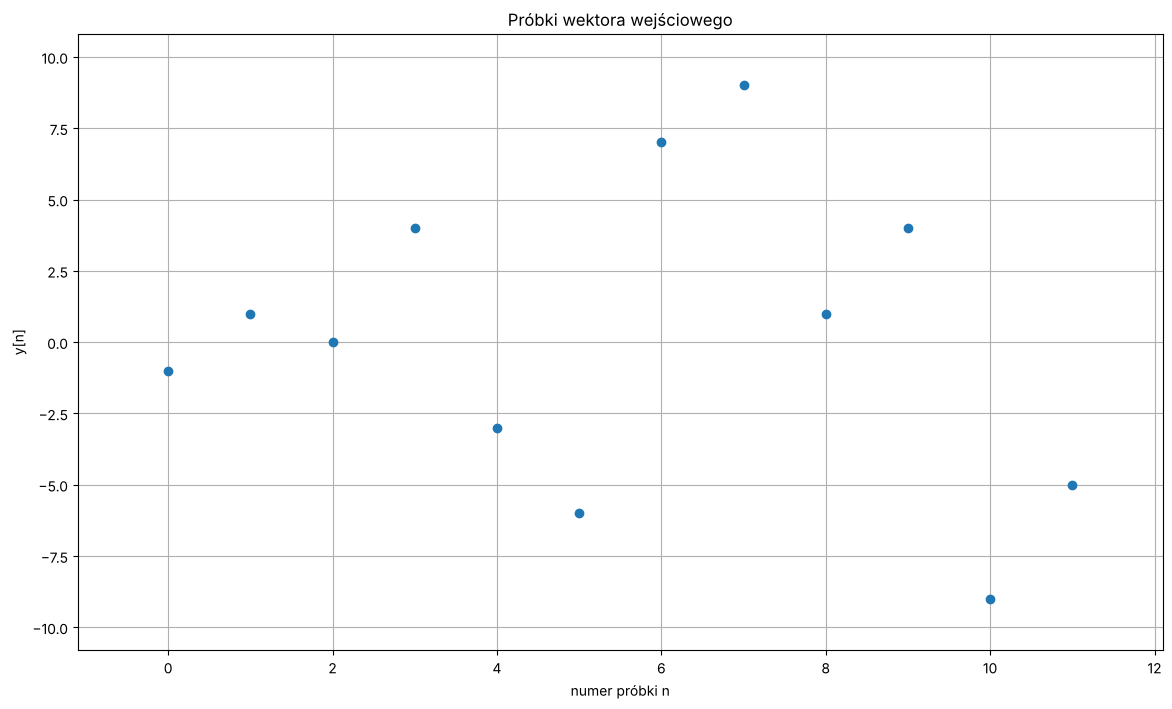

In [2]:
def taskA(y):
    x = np.arange(len(y))                         # numery próbek: 0, 1, ..., len(y)-1

    ymin, ymax = np.min(y), np.max(y)             # najmniejsza i największa wartość
    xmin, xmax = np.min(x), np.max(x)             # pierwszy i ostatni numer próbki
    dy = 0.1 * (ymax - ymin)                      # 10% zakresu na osi y
    dx = 0.1 * (xmax - xmin)                      # 10% zakresu na osi x

    plt.figure(figsize=default_figsize)           # nowe okno
    plt.plot(x, y, 'o')                           # same punkty (bez linii)
    plt.xlim([xmin - dx, xmax + dx])              # oś x z zapasem 10% z obu stron
    plt.ylim([ymin - dy, ymax + dy])              # oś y z zapasem 10% z obu stron
    plt.title('Próbki wektora wejściowego')
    plt.xlabel('numer próbki n')
    plt.ylabel('y[n]')
    plt.grid()
    plt.show()
    return

taskA(test_vec)

### 💡 Wyjaśnienie wyniku

12 punktów, oś y od $-10{,}8$ do $10{,}8$, oś x od $-1{,}1$ do $12{,}1$ – skrajne punkty nie „przyklejają się” do ramki wykresu.

### Zadanie B
Napisz i przetestuj funkcję sortującą i wypisującą elementy wektora wejściowego w porządku zgodnym ze wzrostem modułu.  

Demonstaracja działania najpopularniejszych algorytmów sortowania https://www.toptal.com/developers/sorting-algorithms/


### 📘 Teoria

Sortujemy **według modułu** (wartości bezwzględnej) $|x|$, czyli $-6$ ma „wielkość” 6. Dla `test_vec` kolejność modułów to $0, 1, 1, 1, 3, 4, 4, 5, 6, 7, 9, 9$.

**Sortowanie bąbelkowe (bubble sort)** – najprostszy algorytm:
1. Idziemy po wektorze i porównujemy **sąsiadów** `v[j]` i `v[j+1]`.
2. Jeśli są w złej kolejności (`|v[j]| > |v[j+1]|`) – zamieniamy je miejscami.
3. Po jednym przejściu największy element „wypływa” na koniec jak bąbelek.
4. Powtarzamy $n-1$ razy (za każdym razem można pominąć już ułożony koniec).

Złożoność $O(n^2)$ – wolne dla dużych danych, ale łatwe do zrozumienia. Na koniec porównujemy wynik z wbudowanym `sorted`.

### 🔧 Składnia – użyte funkcje

| Składnia | Co robi |
|---|---|
| `list(data)` | kopia wektora jako lista – **nie modyfikujemy** oryginału przekazanego do funkcji |
| `for i in range(n):` | pętla: `i` przyjmuje wartości `0, 1, ..., n-1` |
| `range(n - 1 - i)` | z każdym przejściem sprawdzamy o jeden element mniej (koniec jest już posortowany) |
| `abs(x)` | wartość bezwzględna liczby |
| `if warunek:` | wykonuje wcięty blok tylko gdy warunek prawdziwy |
| `a, b = b, a` | **zamiana** wartości dwóch zmiennych w jednej linijce (pythonowa sztuczka) |
| `sorted(lista, key=abs)` | wbudowane sortowanie; `key=abs` mówi „porównuj według `abs(x)`” |

In [3]:
def taskB(data):
    v = [int(x) for x in data]                    # kopia danych jako zwykła lista liczb (oryginał zostaje nietknięty)
    n = len(v)                                    # liczba elementów

    for i in range(n - 1):                        # n-1 przejść przez wektor
        for j in range(n - 1 - i):                # porównujemy sąsiadów; ostatnie i elementów już ułożone
            if abs(v[j]) > abs(v[j + 1]):         # zła kolejność według modułu?
                v[j], v[j + 1] = v[j + 1], v[j]   # → zamieniamy sąsiadów miejscami

    print('wejście:            ', [int(x) for x in data])
    print('posortowane (|x|):  ', v)
    print('kontrola – sorted():', sorted([int(x) for x in data], key=abs))   # wbudowane sortowanie dla porównania
    return v

taskB(test_vec);                                  # średnik ukrywa zwracaną wartość (i tak jest wypisana)

wejście:             [-1, 1, 0, 4, -3, -6, 7, 9, 1, 4, -9, -5]
posortowane (|x|):   [0, -1, 1, 1, -3, 4, 4, -5, -6, 7, 9, -9]
kontrola – sorted(): [0, -1, 1, 1, -3, 4, 4, -5, -6, 7, 9, -9]


### 💡 Wyjaśnienie wyniku

Wynik: `[0, -1, 1, 1, -3, 4, 4, -5, -6, 7, 9, -9]` – moduły rosną. Liczby o tym samym module (np. $-1$ i $1$) zostają w **takiej kolejności, w jakiej były na wejściu** – sortowanie bąbelkowe jest **stabilne**, bo zamienia tylko przy ostrej nierówności `>`.

### Zadanie C
Napisz i przetestuj funkcję wyznaczającą pierwiastki wielomianu kwadratowego opisanego wektorem wejściowym (uwaga - nie wolno wykorzystywać funkcji roots), oraz generującą jego wykres (w zakresie $<-4,4>$).

### 📘 Teoria

Wielomian kwadratowy $ax^2+bx+c$. Pierwiastki liczymy ze **wzorów z liceum**:

$$\Delta=b^2-4ac$$

- $\Delta>0$: dwa różne pierwiastki rzeczywiste $\ x_{1,2}=\dfrac{-b\mp\sqrt{\Delta}}{2a}$
- $\Delta=0$: jeden podwójny $\ x_0=\dfrac{-b}{2a}$
- $\Delta<0$: dwa **zespolone** sprzężone $\ x_{1,2}=\dfrac{-b}{2a}\mp j\dfrac{\sqrt{-\Delta}}{2a}$ (wykres nie przecina osi x)

Dla `test_poly` $=x^2+2x-5$: $\Delta=4+20=24$, $\ x_{1,2}=\dfrac{-2\mp\sqrt{24}}{2}=-1\mp\sqrt6\approx-3{,}449;\ 1{,}449$.

### 🔧 Składnia – użyte funkcje

| Składnia | Co robi |
|---|---|
| `polynom.coeffs` | wektor współczynników obiektu `poly1d` → `[1, 2, -5]` |
| `a, b, c = polynom.coeffs` | **rozpakowanie**: pierwszy element do `a`, drugi do `b`, trzeci do `c` |
| `math.sqrt(x)` | pierwiastek kwadratowy (biblioteka `math`, dla liczb nieujemnych) |
| `if / elif / else` | warunki: `elif` = „w przeciwnym razie, jeśli”, `else` = „w każdym innym przypadku” |
| `complex(re, im)` | liczba zespolona `re + im·j` |
| `polynom(x)` | obiekt `poly1d` można wywołać jak funkcję – liczy wartość dla całego wektora `x` |
| `plt.axhline(0, color='k')` | pozioma linia y=0 (oś x), `'k'` = czarny |
| `plt.plot(x1, 0, 'ro')` | czerwona kropka w punkcie (x1, 0) – zaznaczenie pierwiastka |
| `plt.legend()` | legenda z opisami podanymi w `label='...'` |
| `f'tekst {zmienna:.3f}'` | **f-string**: wstawia wartość zmiennej do tekstu; `:.3f` = 3 miejsca po przecinku |

Δ = 24
pierwiastki = [-3.449489742783178, 1.4494897427831779]


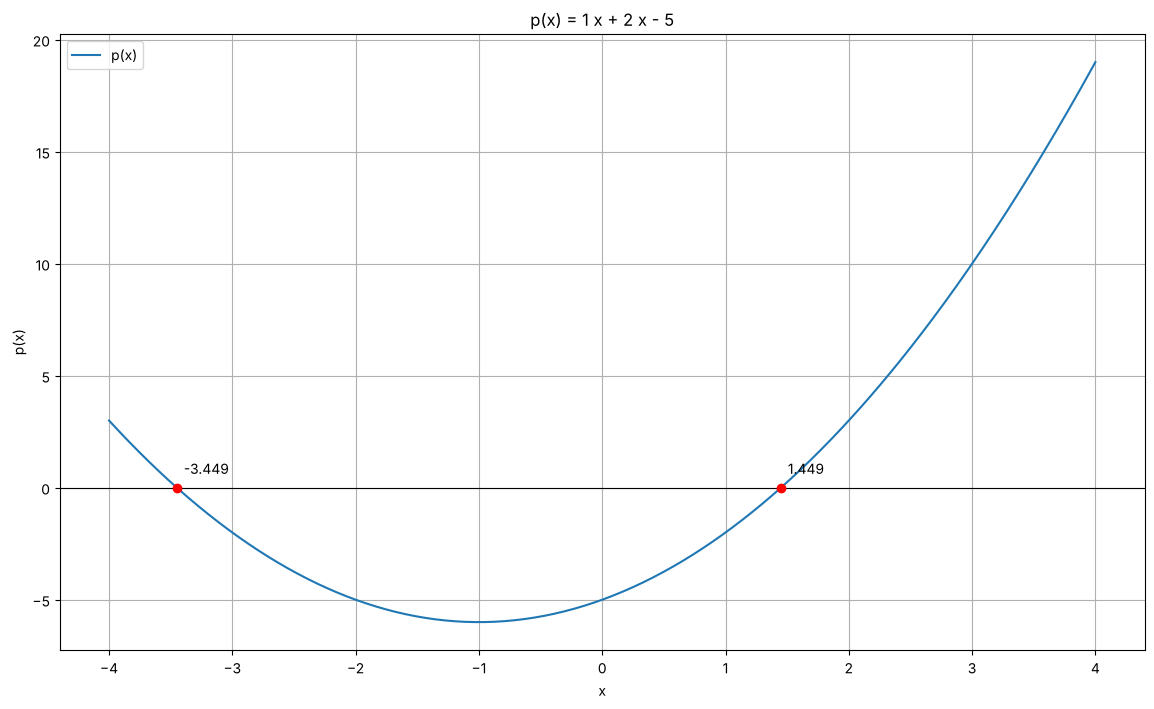

In [4]:
import math                                       # biblioteka z math.sqrt

def taskC(polynom):
    a, b, c = polynom.coeffs                      # współczynniki: a·x² + b·x + c
    delta = b**2 - 4*a*c                          # wyróżnik Δ = b² - 4ac
    print('Δ =', delta)

    if delta > 0:                                 # dwa różne pierwiastki rzeczywiste
        x1 = (-b - math.sqrt(delta)) / (2*a)
        x2 = (-b + math.sqrt(delta)) / (2*a)
        roots = [float(x1), float(x2)]
    elif delta == 0:                              # jeden pierwiastek podwójny
        x0 = -b / (2*a)
        roots = [float(x0)]
    else:                                         # Δ < 0 → pierwiastki zespolone sprzężone
        re = -b / (2*a)                           # część rzeczywista
        im = math.sqrt(-delta) / (2*a)            # część urojona (√(-Δ) bo Δ ujemna)
        roots = [complex(re, -im), complex(re, im)]
    print('pierwiastki =', roots)

    x = np.linspace(-4, 4, 400)                   # 400 punktów w zakresie <-4, 4>
    plt.figure(figsize=default_figsize)
    plt.plot(x, polynom(x), label='p(x)')         # wykres wielomianu
    plt.axhline(0, color='k', linewidth=0.8)      # oś x (linia y = 0)
    for r in roots:                               # zaznaczamy pierwiastki rzeczywiste
        if not isinstance(r, complex):            # (zespolonych nie da się zaznaczyć na osi x)
            plt.plot(r, 0, 'ro')
            plt.annotate(f'{r:.3f}', (r, 0), textcoords='offset points', xytext=(5, 10))  # podpis wartości
    plt.title('p(x) = ' + str(polynom).strip().split('\n')[-1])
    plt.xlabel('x')
    plt.ylabel('p(x)')
    plt.legend()
    plt.grid()
    plt.show()
    return roots

taskC(test_poly);

### 💡 Wyjaśnienie wyniku

- $\Delta=24$, pierwiastki $\approx-3{,}449$ i $1{,}449$ – czerwone kropki leżą dokładnie tam, gdzie parabola przecina oś x.
- Kontrola (tylko do sprawdzenia, w zadaniu nie wolno jej używać): `np.roots([1, 2, -5])` daje to samo.
- Możesz przetestować pozostałe przypadki: `taskC(np.poly1d([1, -2, 1]))` ($\Delta=0$) i `taskC(np.poly1d([1, 0, 4]))` ($\Delta<0$, pierwiastki $\pm 2j$).

### Zadanie D
Napisz i przetestuj funkcję o argumentach będących współczynnikami wielomianu kwadratowego oraz zakresem i dokładnością punktów dziedziny, wykreślającą ten wielomian w podanym zakresie.

### 📘 Teoria

To samo rysowanie co w C, ale **zakres** i **liczba punktów** są parametrami funkcji. Liczba punktów to „dokładność” – im więcej, tym gładsza krzywa (przy np. 5 punktach parabola wygląda jak łamana).

`xrange = [-6, 4]` to lista dwóch liczb: początek i koniec zakresu.

### 🔧 Składnia – użyte funkcje

| Składnia | Co robi |
|---|---|
| `np.poly1d(polynom)` | zamienia listę współczynników na wielomian (jeśli dostaniemy już `poly1d`, nic się nie zmienia) – funkcja działa dla obu typów wejścia |
| `xrange[0]`, `xrange[1]` | pierwszy i drugi element listy (indeksy od **0**) |
| `np.linspace(xrange[0], xrange[1], num_points)` | `num_points` punktów w zadanym zakresie |

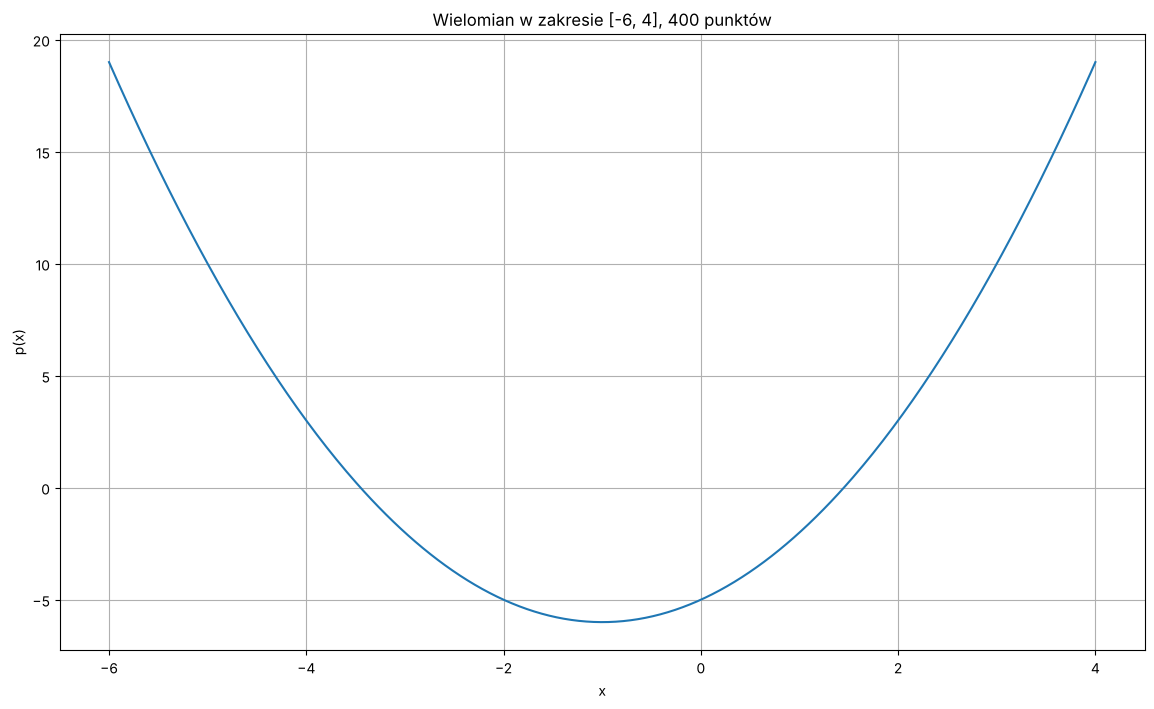

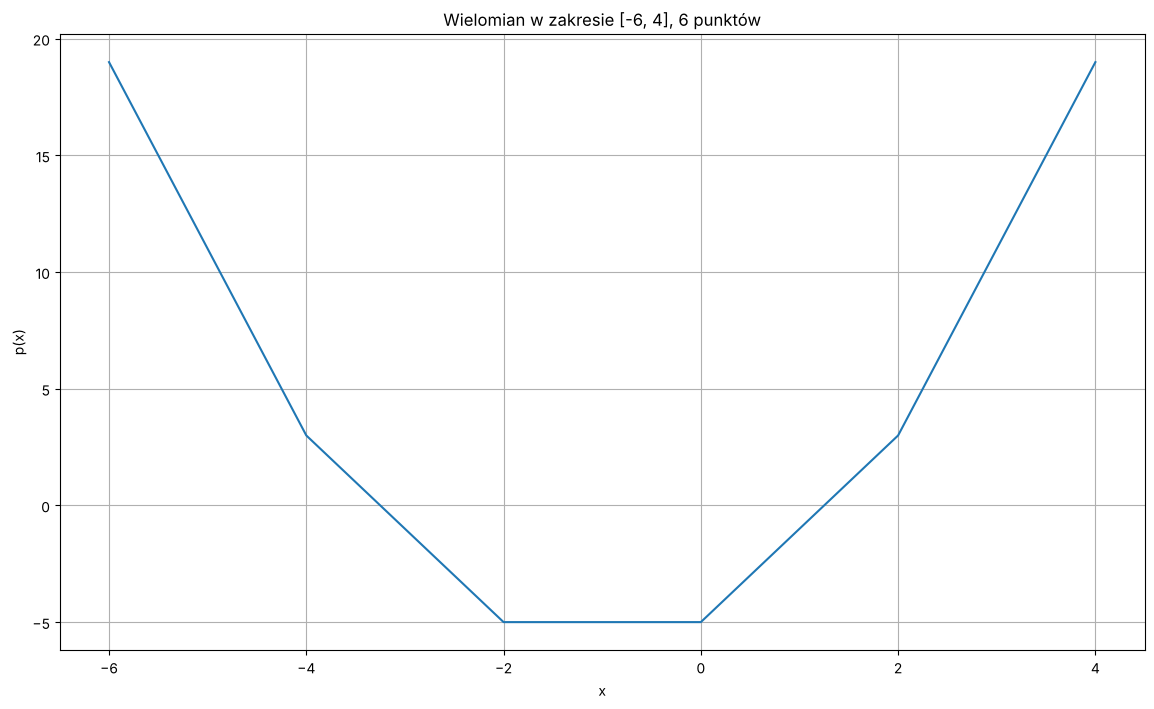

In [5]:
def taskD(polynom, xrange, num_points):
    p = np.poly1d(polynom)                                # zapewniamy, że mamy obiekt wielomianu
    x = np.linspace(xrange[0], xrange[1], num_points)     # num_points punktów od xrange[0] do xrange[1]
    y = p(x)                                              # wartości wielomianu w tych punktach

    plt.figure(figsize=default_figsize)
    plt.plot(x, y)                                        # wykres
    plt.title(f'Wielomian w zakresie {xrange}, {num_points} punktów')
    plt.xlabel('x')
    plt.ylabel('p(x)')
    plt.grid()
    plt.show()
    return

taskD(test_poly, [-6, 4], 400)                            # wywołanie z treści zadania
taskD([1, 2, -5], [-6, 4], 6)                             # dla porównania: tylko 6 punktów → widać łamaną

### 💡 Wyjaśnienie wyniku

Przy 400 punktach parabola jest gładka. Przy 6 punktach widać, że `plt.plot` **łączy punkty prostymi odcinkami** – stąd parametr „dokładności”.

----
## 2. Zadania dodatkowe
----
### Zadanie	E
Napisz i przetestuj funkcję wyliczającą wyznacznik macierzy. Porównać z wynikami generowanymi przez funkcję det().
### Zadanie	F
Napisz prosty kalkulator. Funkcja pobiera argument w postaci  polecenia, np. „3-6” i zwraca wynik działania. Zaimplementować operacje +.-,*,/. 
### Zadanie G
Napisz funkcję tłumaczącą zapis wektorowy wielomianu na zapis tekstowy
### Zadanie H
Napisz funkcję rysującą trójkąt o zadanych (do wyboru):
* długościach 3 boków (tw. cosinusów),
* długościach 2 boków i kąta między nimi (łatwiej).

### Zadanie E – wyznacznik macierzy

### 📘 Teoria

**Rozwinięcie Laplace'a** względem pierwszego wiersza:
$$\det A=\sum_{j=0}^{n-1}(-1)^{j}\,a_{0j}\,\det M_{0j}$$
gdzie $M_{0j}$ to **minor** – macierz $A$ bez wiersza 0 i kolumny $j$. Znaki idą na zmianę $+,-,+,\dots$

To jest **rekurencja**: wyznacznik $n\times n$ liczymy z wyznaczników $(n-1)\times(n-1)$, aż dojdziemy do $1\times1$ (wyznacznik = sam element).

Przykład $2\times2$: $\det\begin{bmatrix}a&b\\c&d\end{bmatrix}=a\cdot d-b\cdot c$.

### 🔧 Składnia – użyte funkcje

| Składnia | Co robi |
|---|---|
| `A.shape[0]` | liczba wierszy macierzy |
| `np.delete(A, 0, axis=0)` | usuwa wiersz 0 (`axis=0` = wiersze, `axis=1` = kolumny) |
| funkcja wywołująca samą siebie | **rekurencja** – musi mieć warunek stopu (tu: macierz 1×1) |
| `np.linalg.det(A)` | wbudowany wyznacznik (do porównania) |
| `np.isclose(a, b)` | czy dwie liczby są równe z dokładnością do błędów zaokrągleń |

In [6]:
def taskE(A):
    A = np.array(A, dtype=float)                       # na wszelki wypadek zamiana na macierz liczb
    n = A.shape[0]                                     # rozmiar macierzy n×n
    if n == 1:                                         # warunek stopu rekurencji
        return A[0, 0]
    det = 0
    for j in range(n):                                 # po kolumnach pierwszego wiersza
        minor = np.delete(np.delete(A, 0, axis=0), j, axis=1)   # bez wiersza 0 i kolumny j
        det += (-1)**j * A[0, j] * taskE(minor)        # znak (-1)^j · element · wyznacznik minora
    return det

M = np.array([[2, -1, 0, 3],
              [1,  4, 2, 0],
              [0, -2, 5, 1],
              [3,  0, 1, 2]])
print('mój wyznacznik:     ', taskE(M))
print('np.linalg.det:      ', np.linalg.det(M))
print('zgodne?             ', np.isclose(taskE(M), np.linalg.det(M)))

mój wyznacznik:      -107.0
np.linalg.det:       -106.99999999999996
zgodne?              True


### 💡 Wyjaśnienie wyniku

Oba sposoby dają ten sam wynik. `np.linalg.det` może pokazać np. `-106.99999999999996` zamiast `-107` – to normalny **błąd zaokrągleń** liczb zmiennoprzecinkowych (liczy inną metodą, rozkładem LU), dlatego porównujemy przez `np.isclose`. Laplace ma złożoność $n!$, więc do dużych macierzy się nie nadaje.

### Zadanie F – prosty kalkulator

### 📘 Teoria

Wejście to tekst, np. `"3-6"`. Trzeba:
1. znaleźć **znak działania** (`+ - * /`),
2. podzielić tekst na lewą i prawą liczbę,
3. zamienić teksty na liczby i wykonać działanie.

Pułapka: **minus na początku** (np. `"-3*2"`) to znak liczby, a nie odejmowanie – dlatego operatora szukamy **od drugiego znaku**. Druga pułapka: **dzielenie przez zero**.

### 🔧 Składnia – użyte funkcje

| Składnia | Co robi |
|---|---|
| `tekst.replace(' ', '')` | usuwa spacje |
| `for i in range(1, len(tekst)):` | pętla po pozycjach tekstu od drugiego znaku |
| `tekst[i]` | znak na pozycji `i` |
| `tekst[:i]`, `tekst[i+1:]` | **wycinki**: wszystko przed pozycją `i` / wszystko po niej |
| `ch in '+-*/'` | czy znak należy do zbioru operatorów |
| `float('3.5')` | zamiana tekstu na liczbę |
| `return` w środku pętli | natychmiast kończy funkcję |

In [7]:
def taskF(polecenie):
    s = polecenie.replace(' ', '')                     # usuwamy spacje: "3 - 6" → "3-6"
    for i in range(1, len(s)):                         # od 2. znaku – pierwszy minus to znak liczby
        if s[i] in '+-*/' and s[i-1] not in 'eE':      # znaleziony operator (i nie część zapisu 1e-3)
            a = float(s[:i])                           # lewa liczba
            b = float(s[i+1:])                         # prawa liczba
            op = s[i]                                  # operator
            if op == '+':
                return a + b
            if op == '-':
                return a - b
            if op == '*':
                return a * b
            if op == '/':
                if b == 0:                             # dzielenie przez zero
                    return 'błąd: dzielenie przez zero'
                return a / b
    return 'błąd: brak operatora'                      # pętla nie znalazła działania

for p in ['3-6', '2.5*4', '-3*2', '7/2', '10 + -4', '5/0']:
    print(f'{p:>8}  =  {taskF(p)}')

     3-6  =  -3.0
   2.5*4  =  10.0
    -3*2  =  -6.0
     7/2  =  3.5
 10 + -4  =  6.0
     5/0  =  błąd: dzielenie przez zero


### Zadanie G – wielomian z wektora na tekst

### 📘 Teoria

Wektor $[a_n, \dots, a_1, a_0]$ ma długość $n+1$, więc element o indeksie $i$ stoi przy potędze $n-i$. Przykład: $[1, 2, -5]$ → $x^2 + 2x - 5$.

Zasady ładnego zapisu: pomijamy wyrazy z zerem, nie piszemy `1x` tylko `x`, nie piszemy `x^1` tylko `x`, nie piszemy `x^0`, a minus wstawiamy zamiast plusa.

### 🔧 Składnia – użyte funkcje

| Składnia | Co robi |
|---|---|
| `enumerate(lista)` | pętla dająca jednocześnie **indeks i wartość**: `for i, a in enumerate(v):` |
| `continue` | przeskakuje do następnego obrotu pętli |
| `str(x)` | zamiana liczby na tekst |
| `lista.append(x)` | dopisanie elementu na koniec listy |
| `' '.join(lista)` | sklejenie elementów listy w jeden tekst ze spacjami |

In [8]:
def taskG(v):
    n = len(v) - 1                                  # stopień wielomianu
    czesci = []                                     # tu zbieramy kolejne wyrazy jako tekst
    for i, a in enumerate(v):                       # i – indeks, a – współczynnik
        p = n - i                                   # potęga x dla tego współczynnika
        if a == 0:                                  # zerowy wyraz pomijamy
            continue
        znak = '-' if a < 0 else '+'                # znak wyrazu
        a = abs(a)                                  # dalej pracujemy na wartości bez znaku
        a_txt = '' if (a == 1 and p != 0) else str(a)   # „1x” → „x” (ale wyraz wolny 1 zostaje)
        if p == 0:
            x_txt = ''                              # wyraz wolny – bez x
        elif p == 1:
            x_txt = 'x'                             # x^1 → x
        else:
            x_txt = 'x^' + str(p)                   # x^p
        czesci.append(znak)
        czesci.append(a_txt + x_txt)
    if not czesci:                                  # same zera
        return '0'
    if czesci[0] == '+':                            # plus na samym początku jest zbędny
        czesci = czesci[1:]
    else:
        czesci = ['-' + czesci[1]] + czesci[2:]     # minus przyklejamy do pierwszego wyrazu
    return ' '.join(czesci)

for v in [[1, 2, -5], [1, 1, -1, 0, -1], [-1, 0, 0, 1], [3, -1, 0], [0, 0, 7]]:
    print(f'{str(v):>18}  →  {taskG(v)}')

        [1, 2, -5]  →  x^2 + 2x - 5
 [1, 1, -1, 0, -1]  →  x^4 + x^3 - x^2 - 1
     [-1, 0, 0, 1]  →  -x^3 + 1
        [3, -1, 0]  →  3x^2 - x
         [0, 0, 7]  →  7


### Zadanie H – rysowanie trójkąta

### 📘 Teoria

**Wariant łatwiejszy: dwa boki $a$, $b$ i kąt $\gamma$ między nimi.**
Stawiamy wierzchołek $A=(0,0)$, bok $a$ kładziemy na osi x, więc $B=(a,0)$. Bok $b$ wychodzi z $A$ pod kątem $\gamma$:
$$C=(b\cos\gamma,\ b\sin\gamma)$$

**Wariant: trzy boki $a, b, c$.** Kąt między $a$ i $b$ (naprzeciw boku $c$) dostajemy z **twierdzenia cosinusów**:
$$c^2=a^2+b^2-2ab\cos\gamma\ \Rightarrow\ \cos\gamma=\frac{a^2+b^2-c^2}{2ab}$$
i rysujemy jak wyżej. Trójkąt istnieje tylko gdy spełniona jest **nierówność trójkąta** (każdy bok krótszy od sumy dwóch pozostałych).

### 🔧 Składnia – użyte funkcje

| Składnia | Co robi |
|---|---|
| `np.radians(st)` | stopnie → radiany (funkcje `np.sin/np.cos` chcą radianów) |
| `np.arccos(x)` | arcus cosinus – kąt w radianach, którego cosinus to `x` |
| `np.degrees(rad)` | radiany → stopnie |
| `plt.fill(x, y, alpha=0.3)` | wypełniony wielokąt; `alpha` = przezroczystość (0–1) |
| `plt.axis('equal')` | **ta sama skala** na obu osiach – inaczej trójkąt byłby zniekształcony |
| `x + [x[0]]` | dopisanie pierwszego punktu na koniec, żeby linia się „zamknęła” |

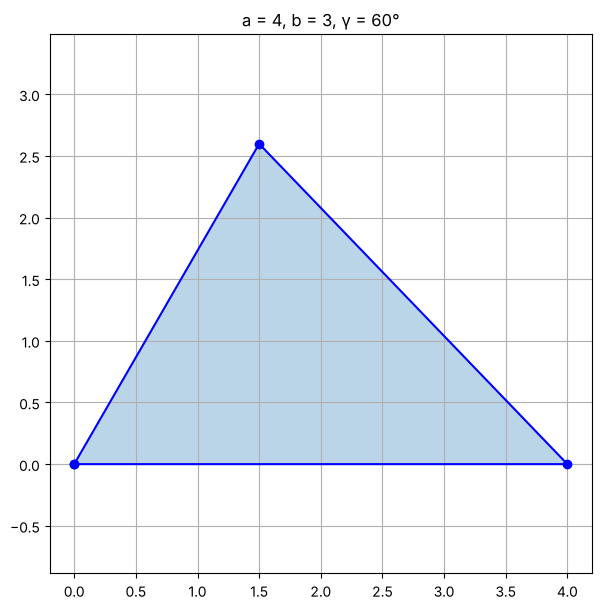

kąt między a i b: 90.00°


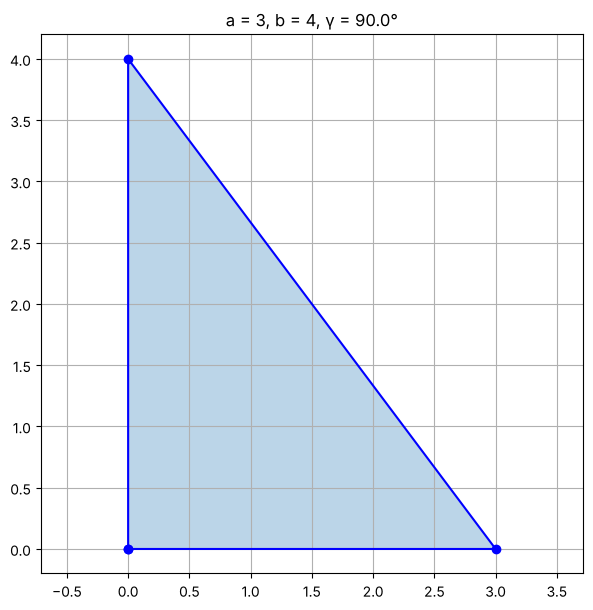

Z takich boków nie da się zbudować trójkąta


In [9]:
def taskH_dwa_boki(a, b, kat_stopnie):
    g = np.radians(kat_stopnie)                       # kąt γ w radianach
    xs = [0, a, b*np.cos(g)]                          # x wierzchołków A, B, C
    ys = [0, 0, b*np.sin(g)]                          # y wierzchołków A, B, C

    plt.figure(figsize=(7, 7))
    plt.fill(xs, ys, alpha=0.3)                       # wypełnienie trójkąta
    plt.plot(xs + [xs[0]], ys + [ys[0]], 'b-o')       # obwód (z powrotem do A) + kropki w wierzchołkach
    plt.title(f'a = {a}, b = {b}, γ = {kat_stopnie}°')
    plt.axis('equal')                                 # równa skala osi – bez zniekształceń
    plt.grid()
    plt.show()

def taskH_trzy_boki(a, b, c):
    if a + b <= c or a + c <= b or b + c <= a:        # nierówność trójkąta
        print('Z takich boków nie da się zbudować trójkąta')
        return
    cos_g = (a**2 + b**2 - c**2) / (2*a*b)            # twierdzenie cosinusów
    kat = np.degrees(np.arccos(cos_g))                # kąt γ w stopniach
    print(f'kąt między a i b: {kat:.2f}°')
    taskH_dwa_boki(a, b, kat)                         # dalej rysujemy jak dla 2 boków i kąta

taskH_dwa_boki(4, 3, 60)
taskH_trzy_boki(3, 4, 5)                              # trójkąt prostokątny → kąt 90°
taskH_trzy_boki(1, 2, 5)                              # niemożliwy

### 💡 Wyjaśnienie wyniku

Dla boków 3, 4, 5 wychodzi kąt $90°$ – to klasyczny trójkąt prostokątny ($3^2+4^2=5^2$), więc twierdzenie cosinusów działa poprawnie.

---
# 🎓 Kolokwium – przykładowe pytania z rozwiązaniami
Pytania oznaczone **[z kolokwium]** to prawdziwe przykłady od prowadzącego, pozostałe są **wymyślone w tym samym stylu**. Przy każdym:
- **Odpowiedź (do wpisania)** – krótki tekst, który można wpisać w pole odpowiedzi,
- **Jak to rozwiązać** – kroki, żeby umieć zrobić podobne zadanie samemu,
- kod tam, gdzie zadanie wymaga obliczeń lub wykresu (na kolokwium można dołączyć zrzut wykresu jako obrazek).

### Pytanie 1
Bez użycia `np.roots` wyznacz pierwiastki wielomianu $x^2+4x+5$. Jakie to pierwiastki?

**Jak to rozwiązać:** $\Delta=b^2-4ac$; jeśli $\Delta<0$, to $x_{1,2}=\frac{-b}{2a}\pm j\frac{\sqrt{-\Delta}}{2a}$. Można użyć funkcji `taskC` z tego notatnika.

**Odpowiedź (do wpisania):** $\Delta=16-20=-4<0$ → pierwiastki zespolone sprzężone $x_{1,2}=-2\pm j$. Parabola nie przecina osi x (leży cała nad nią, minimum $1$ w $x=-2$).

Δ = -4
pierwiastki = [(-2-1j), (-2+1j)]


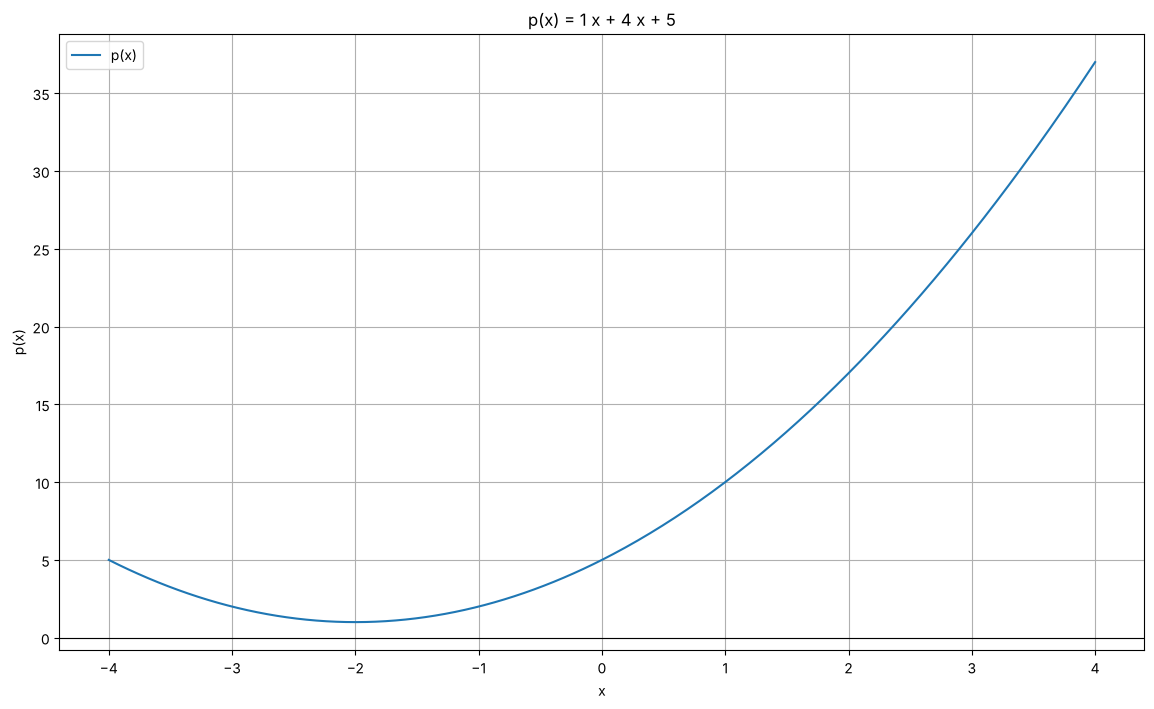

In [10]:
taskC(np.poly1d([1, 4, 5]));      # Δ = -4 → -2 ± 1j

### Pytanie 2
Posortuj wektor `[3, -7, 2, -1, 5]` rosnąco według modułu, nie używając `sort`/`sorted`.

**Jak to rozwiązać:** sortowanie bąbelkowe – porównuj sąsiadów `abs(v[j]) > abs(v[j+1])` i zamieniaj (funkcja `taskB`).

**Odpowiedź (do wpisania):** `[-1, 2, 3, 5, -7]`.

In [11]:
taskB(np.array([3, -7, 2, -1, 5]));

wejście:             [3, -7, 2, -1, 5]
posortowane (|x|):   [-1, 2, 3, 5, -7]
kontrola – sorted(): [-1, 2, 3, 5, -7]


### Pytanie 3 (teoria / Python)
Co robi `plt.subplot(2, 3, 5)`?

**Odpowiedź (do wpisania):** dzieli okno wykresu na siatkę 2 wiersze × 3 kolumny i wybiera pole nr 5 (numeracja od 1 wierszami → drugi wiersz, środkowa kolumna). Kolejne `plt.plot`, `plt.title` itd. rysują w tym polu.

### Pytanie 4
Wyznacznik macierzy $\begin{bmatrix}1&2\\3&4\end{bmatrix}$ policz ręcznie i sprawdź funkcją `taskE` oraz `np.linalg.det`.

**Odpowiedź (do wpisania):** $1\cdot4-2\cdot3=-2$.

In [12]:
print(taskE([[1, 2], [3, 4]]), np.linalg.det([[1, 2], [3, 4]]))

-2.0 -2.0000000000000004


---
## 📝 Ściąga – Laboratorium 2

**Python – podstawy**
| | |
|---|---|
| `def f(arg):` + wcięcie, `return wynik` | własna funkcja |
| `for i in range(n):` / `for i, x in enumerate(v):` | pętle (z indeksem) |
| `if ...: / elif ...: / else:` | warunki |
| `a, b = b, a` | zamiana wartości |
| `lista[i]`, `lista[:i]`, `lista[i+1:]` | element, wycinki |
| `len(x)`, `abs(x)`, `float('3')`, `str(3)` | długość, moduł, konwersje |
| `sorted(v, key=abs)` | sortowanie według klucza |
| `f'{x:.3f}'` | f-string z 3 miejscami po przecinku |

**numpy**
| | |
|---|---|
| `np.array([...])`, `np.arange(n)` | wektor, wektor 0..n-1 |
| `np.delete(A, i, axis=0/1)` | usunięcie wiersza/kolumny |
| `np.linalg.det(A)` | wyznacznik |
| `np.isclose(a, b)` | porównanie liczb z tolerancją |
| `np.radians, np.degrees, np.arccos` | kąty |

**matplotlib**
| | |
|---|---|
| `plt.plot(x, y, 'o')` | same punkty |
| `plt.xlim([a, b])`, `plt.ylim([a, b])` | zakres osi |
| `plt.axhline(0)` | linia pozioma |
| `plt.fill(x, y, alpha=0.3)` | wypełniony wielokąt |
| `plt.axis('equal')` | równa skala osi |
| `plt.legend()` + `label='...'` | legenda |

**Wzory:** $\Delta=b^2-4ac$, $x_{1,2}=\frac{-b\mp\sqrt\Delta}{2a}$; tw. cosinusów $c^2=a^2+b^2-2ab\cos\gamma$.